# Plotting

In [10]:
%load_ext autoreload
%autoreload 2
from lib.latex_plots import configure_matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

configure_matplotlib()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
DATA = Path("../data")
PROCESSED = DATA / "processed"
FIGS = Path("../plots/adri")

df = pd.read_parquet(PROCESSED / "apc_oa_works.parquet")

## Has Catalan science moved to open access?

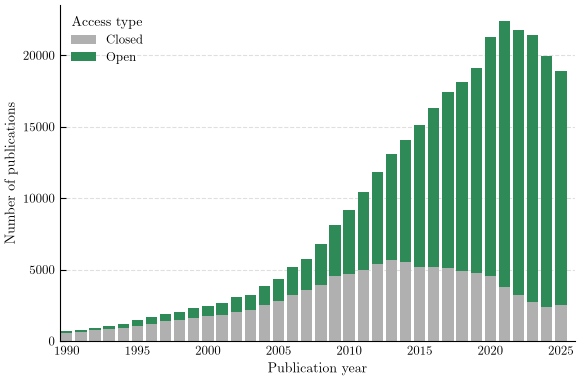

In [12]:
def plot_open_vs_closed_by_year(
    df: pd.DataFrame,
    *,
    min_year: int | None = None,
    max_year: int | None = None,
    as_percentage: bool = False,
    save_path: Path | None = None,
    figsize: tuple[float, float] = (10, 5.5),
):
    """
    Stacked bar chart: open access vs closed publications per year.

    Parameters
    ----------
    df : DataFrame with 'year' (int) and 'is_open_access' (bool).
    min_year, max_year : optional year bounds (inclusive).
    as_percentage : if True, normalise each year's stack to 100 %.
    save_path : optional Path to save the figure (PNG/PDF/SVG).
    """
    data = df.dropna(subset=["year", "is_open_access"]).copy()
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]

    # Count papers per year × OA status
    counts = (
        data.groupby(["year", "is_open_access"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    # Ensure both columns exist even if one status is missing
    for col in (False, True):
        if col not in counts.columns:
            counts[col] = 0
    # display(counts)
    
    if as_percentage:
        plot_data = counts.div(counts.sum(axis=1), axis=0) * 100
    else:
        plot_data = counts

    years = plot_data.index.astype(int)
    closed_vals = plot_data[False].values
    open_vals = plot_data[True].values

    fig, ax = plt.subplots(figsize=figsize)

    color_closed = "#B0B0B0"   # neutral grey
    color_open   = "#2E8B57"   # sea green

    ax.bar(years, closed_vals, label="Closed", color=color_closed, width=0.8)
    ax.bar(years, open_vals, bottom=closed_vals, label="Open",
           color=color_open, width=0.8)

    # --- Styling -------------------------------------------------------------
    ax.set_xlabel("Publication year")
    if as_percentage:
        ax.set_ylabel("Share of publications (%)")
        ax.set_ylim(0, 100)
    else:
        ax.set_ylabel("Number of publications")

    # ax.set_title("Open access vs. closed publications by year (Catalonia)",
    #              pad=12, fontsize=13, weight="semibold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    # ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=0)

    ax.legend(title="Access type", frameon=False, loc="upper left")

    if save_path is not None:
        fig.tight_layout()
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    fig.tight_layout()
    return fig, ax


fig, ax = plot_open_vs_closed_by_year(df, min_year=1990, max_year=2025, figsize=(6, 4))
# ax.set_yscale('log')
ax.set_xlim(1989.5, 2026)
fig.savefig(FIGS / "open_vs_closed_by_year.pdf", bbox_inches="tight")
fig.savefig(FIGS / "open_vs_closed_by_year.png", bbox_inches="tight")
plt.show()

Total fit:  {'a': -228.4065421795631, 'b': 0.11811942794009145, 'se_b': 0.0018208353883165352, 'r2': 0.9933903771216862, 'ssr': 0.2086407343074151, 'n': 30}
OA fit:     {'a': -326.1143113496271, 'b': 0.16637020127180183, 'se_b': 0.0025065165400446074, 'r2': 0.9936846607855288, 'ssr': 0.39536560166300677, 'n': 30}
Slope test: {'F': 242.56313333787065, 'df1': 1, 'df2': 56, 'p': 5.218579087550329e-22}


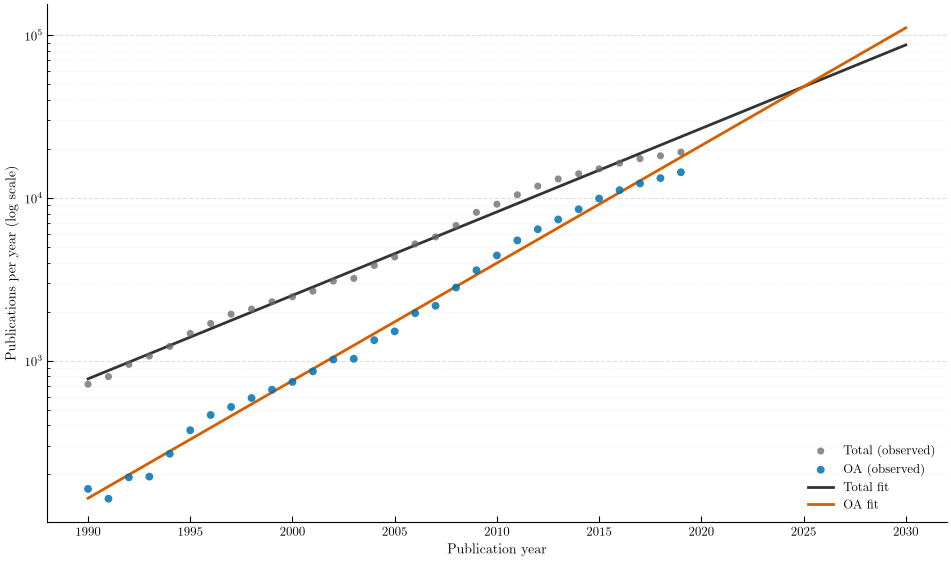

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    from scipy import stats as _stats
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False


# ---------------------------------------------------------------------------
# Regresión log-lineal (exponencial)
# ---------------------------------------------------------------------------
def _fit_loglinear(years, counts):
    """Ajusta log(count) = a + b·year y devuelve a, b, SE(b), R², n."""
    years = np.asarray(years, dtype=float)
    y = np.asarray(counts, dtype=float)
    n = len(years)
    log_y = np.log(y)
    X = np.column_stack([np.ones(n), years])
    beta, *_ = np.linalg.lstsq(X, log_y, rcond=None)
    resid = log_y - X @ beta
    ssr = float(resid @ resid)
    dof = n - 2
    se_b = np.nan
    if dof > 0:
        sigma2 = ssr / dof
        XtX_inv = np.linalg.inv(X.T @ X)
        se_b = float(np.sqrt(sigma2 * XtX_inv[1, 1]))
    ss_tot = float(np.sum((log_y - log_y.mean()) ** 2))
    r2 = 1 - ssr / ss_tot if ss_tot > 0 else 1.0
    return dict(a=float(beta[0]), b=float(beta[1]), se_b=se_b,
                r2=r2, ssr=ssr, n=n)


# ---------------------------------------------------------------------------
# Test ANCOVA: H0 = pendientes iguales entre dos grupos
# ---------------------------------------------------------------------------
def _test_equal_slopes(years, counts, groups):
    """
    F-test de igualdad de pendientes en un modelo log-lineal.

        H0 : b_grupo0 == b_grupo1   (interceptos pueden diferir)

    Compara:
      * modelo completo   : log(y) = a_g + b_g · year  (uno por grupo)
      * modelo reducido   : log(y) = a_g + b  · year   (pendiente común)

    Devuelve F, gl, p. Si scipy no está disponible, p = NaN.
    """
    years  = np.asarray(years,  dtype=float)
    y      = np.asarray(counts, dtype=float)
    groups = np.asarray(groups)
    log_y  = np.log(y)
    uniq   = np.unique(groups)

    # Modelo completo
    ssr_full, k_full = 0.0, 0
    for g in uniq:
        m = groups == g
        X = np.column_stack([np.ones(m.sum()), years[m]])
        beta, *_ = np.linalg.lstsq(X, log_y[m], rcond=None)
        r = log_y[m] - X @ beta
        ssr_full += float(r @ r)
        k_full   += X.shape[1]

    # Modelo reducido (pendiente compartida)
    cols = [np.ones(len(years)), years] + [
        (groups == g).astype(float) for g in uniq[1:]
    ]
    Xr = np.column_stack(cols)
    br, *_ = np.linalg.lstsq(Xr, log_y, rcond=None)
    r_r = log_y - Xr @ br
    ssr_red = float(r_r @ r_r)
    k_red   = Xr.shape[1]

    n   = len(years)
    df1 = k_full - k_red
    df2 = n - k_full
    if df2 <= 0 or ssr_full <= 0:
        return dict(F=np.nan, df1=df1, df2=df2, p=np.nan)

    F = max(((ssr_red - ssr_full) / df1) / (ssr_full / df2), 0.0)
    p = _stats.f.sf(F, df1, df2) if HAS_SCIPY else np.nan
    return dict(F=float(F), df1=int(df1), df2=int(df2), p=float(p))


# ---------------------------------------------------------------------------
# Plot comparativo
# ---------------------------------------------------------------------------
def plot_oa_vs_total_exponential(
    df: pd.DataFrame,
    *,
    min_year: int | None = None,
    max_year: int | None = None,
    oa_column: str = "is_open_access",
    extrapolate_to: int | None = None,
    annotate: bool = True,
    save_path: Path | None = None,
    figsize: tuple[float, float] = (9.5, 5.6),
):
    """
    Compara el ajuste exponencial de las publicaciones OA con el del
    corpus total, y contrasta H0: b_OA == b_total.

    Interpretación
    --------------
    * b_OA ≈ b_total  →  misma tasa de crecimiento ⇒ la cuota OA
      permanece aproximadamente constante en el tiempo.
    * b_OA > b_total  →  OA crece más rápido ⇒ su cuota está subiendo
      (adopción diferencial de OA).
    * b_OA ≈ b_total > 0  y  cuota OA ya elevada  →  el crecimiento
      exponencial del corpus es esencialmente el crecimiento
      exponencial del subconjunto OA.
    """
    data = df.dropna(subset=["year", oa_column]).copy()
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]

    total_counts = data.groupby("year").size().sort_index().astype(float)
    oa_counts = (
        data[data[oa_column]]
        .groupby("year").size()
        .reindex(total_counts.index, fill_value=0)
        .astype(float)
    )

    # log(0) no está definido: conservamos sólo años con OA > 0
    # (misma rejilla para ambas regresiones ⇒ comparación justa).
    valid = (total_counts > 0) & (oa_counts > 0)
    n_dropped = int((~valid).sum())
    total_counts = total_counts[valid]
    oa_counts    = oa_counts[valid]
    if len(total_counts) < 3:
        raise ValueError(
            f"Se necesitan ≥3 años válidos (hay {len(total_counts)})."
        )

    years = total_counts.index.to_numpy(dtype=float)

    fit_total = _fit_loglinear(years, total_counts.to_numpy())
    fit_oa    = _fit_loglinear(years, oa_counts.to_numpy())

    # Test H0: pendientes iguales (sobre datos apilados)
    slope_test = _test_equal_slopes(
        np.concatenate([years, years]),
        np.concatenate([total_counts.to_numpy(), oa_counts.to_numpy()]),
        np.concatenate([np.zeros(len(years)), np.ones(len(years))]),
    )

    # --- Plot ---------------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)

    x_end = extrapolate_to if extrapolate_to is not None else years.max()
    xx = np.linspace(years.min(), x_end, 300)

    ax.scatter(years, total_counts, s=26, color="#666666", alpha=0.75,
               edgecolors="none", zorder=3, label="Total (observed)")
    ax.scatter(years, oa_counts, s=32, color="#0072B2", alpha=0.85,
               edgecolors="none", zorder=4, label="OA (observed)")
    ax.plot(xx, np.exp(fit_total["a"] + fit_total["b"] * xx),
            color="#333333", linewidth=2, zorder=2, label="Total fit")
    ax.plot(xx, np.exp(fit_oa["a"] + fit_oa["b"] * xx),
            color="#D55E00", linewidth=2, zorder=2, label="OA fit")

    ax.set_yscale("log")
    ax.set_xlabel("Publication year")
    ax.set_ylabel("Publications per year (log scale)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, which="major", axis="y", linestyle="--", alpha=0.4)
    ax.grid(True, which="minor", axis="y", linestyle=":",  alpha=0.2)
    ax.set_axisbelow(True)

    def _growth(f):
        g = (np.exp(f["b"]) - 1) * 100
        d = np.log(2) / f["b"] if f["b"] > 0 else np.nan
        return g, d

    g_t, d_t = _growth(fit_total)
    g_o, d_o = _growth(fit_oa)
    share_first = oa_counts.iloc[0] / total_counts.iloc[0] * 100
    share_last  = oa_counts.iloc[-1] / total_counts.iloc[-1] * 100
    
    if annotate:

        lines = [
            f"{'':8s}  b (±SE)            R²log   growth   doubling",
            f"Total    {fit_total['b']:+.4f} ± {fit_total['se_b']:.4f}"
            f"   {fit_total['r2']:.3f}   {g_t:5.1f}%   {d_t:4.1f} yr",
            f"OA       {fit_oa['b']:+.4f} ± {fit_oa['se_b']:.4f}"
            f"   {fit_oa['r2']:.3f}   {g_o:5.1f}%   {d_o:4.1f} yr",
            "",
        ]
        if not np.isnan(slope_test["p"]):
            verdict = ("slopes indistinguishable (p > 0.05)"
                       if slope_test["p"] > 0.05
                       else "slopes differ significantly (p ≤ 0.05)")
            lines.append(
                f"H0: b_OA = b_total   F({slope_test['df1']},"
                f"{slope_test['df2']}) = {slope_test['F']:.2f}, "
                f"p = {slope_test['p']:.3f}"
            )
            lines.append(f"→ {verdict}")
        lines.append(
            f"OA share:  {share_first:.1f}% ({int(years[0])})"
            f"  →  {share_last:.1f}% ({int(years[-1])})"
        )
        if n_dropped:
            lines.append(f"({n_dropped} year(s) dropped: OA count = 0)")

        ax.text(0.02, 0.97, "\n".join(lines),
                transform=ax.transAxes, ha="left", va="top",
                fontsize=8.5, family="monospace",
                bbox=dict(boxstyle="round,pad=0.4",
                          facecolor="white", edgecolor="#cccccc",
                          alpha=0.93))

    ax.legend(frameon=False, loc="lower right", fontsize=9)

    if save_path is not None:
        save_path = Path(save_path)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        if save_path.suffix.lower() != ".pdf":
            fig.savefig(save_path.with_suffix(".pdf"),
                        bbox_inches="tight")

    return fig, ax, dict(fit_total=fit_total, fit_oa=fit_oa,
                         slope_test=slope_test)


# --- Uso ---------------------------------------------------------------------
fig, ax, res = plot_oa_vs_total_exponential(
    df,
    min_year=1990,
    max_year=2019,
    extrapolate_to=2030,
    annotate=False,
    # save_path=FIGS / "oa_vs_total_exponential.png",
)
print("Total fit: ", res["fit_total"])
print("OA fit:    ", res["fit_oa"])
print("Slope test:", res["slope_test"])
plt.show()

## Top publishers by year. Are we dependent on some publishers? 

                                                n_papers  share_pct  \
publisher_name                                                        
Elsevier BV                                        94870  28.716375   
Wiley                                              31365   9.493930   
Springer Science+Business Media                    24544   7.429268   
Multidisciplinary Digital Publishing Institute     16193   4.901489   
Oxford University Press                            11168   3.380462   
Other                                             152229  46.078476   

                                                n_open_access  pct_open_access  
publisher_name                                                                  
Elsevier BV                                             51834        54.636872  
Wiley                                                   17742        56.566236  
Springer Science+Business Media                         12923        52.652379  
Multidisciplinary Digital 

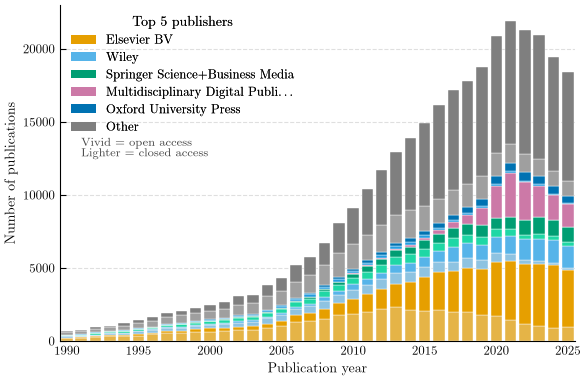

In [21]:
from pathlib import Path
import colorsys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch


def _truncate(label: str, n: int = 30) -> str:
    label = str(label)
    return label if len(label) <= n else label[: n - 1] + "…"


def _dim(color: str, amount: float = 0.45) -> tuple:
    """Desaturate + lighten a colour for the 'closed access' segments.

    Done in HLS space so bright colours like yellow (#F0E442) don't wash
    out into white when dimmed.
    """
    r, g, b = to_rgb(color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    new_l = l + (1 - l) * amount
    new_s = s * (1 - amount)
    return colorsys.hls_to_rgb(h, new_l, new_s)


def plot_top_publishers_by_year(
    df: pd.DataFrame,
    *,
    top_n: int = 5,
    include_other: bool = True,
    min_year: int | None = None,
    max_year: int | None = None,
    aggregation_column: str = "publisher_name",
    oa_column: str = "is_open_access",
    save_path: Path | None = None,
    figsize: tuple[float, float] = (8, 4.5),
):
    """
    Stacked bar chart per year of papers from the top-N publishers
    (by total count across the whole period), split into open vs closed
    access within each publisher:

        - vivid colour  = open access papers
        - dimmed colour = closed access papers

    Returns (fig, ax, summary).
    """
    data = df.dropna(subset=["year", aggregation_column, oa_column]).copy()
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]

    if data.empty:
        raise ValueError("No data left after filtering.")

    totals = data.groupby(aggregation_column).size().sort_values(ascending=False)
    top_pubs = totals.head(top_n).index.tolist()

    data["aggregated_group"] = data[aggregation_column].where(
        data[aggregation_column].isin(top_pubs), "Other"
    )

    years = np.sort(data["year"].unique().astype(int))

    def _pivot(mask: pd.Series) -> pd.DataFrame:
        return (
            data[mask]
            .groupby(["year", "aggregated_group"]).size()
            .unstack(fill_value=0)
            .reindex(index=years, fill_value=0)
        )

    pivot_open = _pivot(data[oa_column])
    pivot_closed = _pivot(~data[oa_column])

    all_cols = set(pivot_open.columns) | set(pivot_closed.columns)
    order = [p for p in top_pubs if p in all_cols]
    if include_other and "Other" in all_cols:
        order.append("Other")

    # Okabe-Ito colourblind-safe palette (matches the user's)'#D55E00', '#CC79A7'
    base_colors = ['#E69F00', '#56B4E9', '#009E73', '#CC79A7', '#0072B2']
    if include_other:
        base_colors = base_colors + ["#7F7F7F"]

    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(len(years), dtype=float)

    pub_handles = []
    for i, pub in enumerate(order):
        closed_vals = (
            pivot_closed[pub].to_numpy(dtype=float)
            if pub in pivot_closed.columns else np.zeros(len(years))
        )
        open_vals = (
            pivot_open[pub].to_numpy(dtype=float)
            if pub in pivot_open.columns else np.zeros(len(years))
        )

        vivid = base_colors[i] if i < len(base_colors) else "#888888"
        dimmed = _dim(vivid, 0.25)

        # closed (dim) at the bottom, open (vivid) on top
        ax.bar(years, closed_vals, bottom=bottom, width=0.8,
               color=dimmed, edgecolor="white", linewidth=0.3)
        bottom += closed_vals
        ax.bar(years, open_vals, bottom=bottom, width=0.8,
               color=vivid, edgecolor="white", linewidth=0.3)
        bottom += open_vals

        pub_handles.append(Patch(facecolor=vivid, label=_truncate(pub, 32)))

    # --- Styling -------------------------------------------------------------
    ax.set_xlabel("Publication year")
    ax.set_ylabel("Number of publications")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=0)

    # Publisher legend (upper-left)
    leg_pub = ax.legend(
        handles=pub_handles,
        title=f"Top {top_n} publishers",
        loc="upper left", frameon=False,
    )
    ax.add_artist(leg_pub)

    # Access-type hint as small text (keeps the plot clean, no 2nd legend)
    ax.annotate(
        xy=(1991, 12500),
        text="Vivid = open access\nLighter = closed access",
        transform=ax.transAxes, ha="left", va="bottom",
        fontsize=8.5, style="italic", color="#444",
    )

    fig.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    # --- Summary table -------------------------------------------------------
    total_papers = int(totals.sum())
    summary = totals.head(top_n).to_frame(name="n_papers")
    summary["share_pct"] = 100 * summary["n_papers"] / total_papers

    oa_counts = data[data[oa_column]].groupby(aggregation_column).size()
    summary["n_open_access"] = summary.index.map(oa_counts).fillna(0).astype(int)
    summary["pct_open_access"] = 100 * summary["n_open_access"] / summary["n_papers"]

    if include_other:
        rest = totals.iloc[top_n:]
        if not rest.empty:
            other_total = int(rest.sum())
            other_oa = int(data.loc[
                (~data[aggregation_column].isin(top_pubs)) & (data[oa_column])
            ].shape[0])
            summary.loc["Other"] = [
                other_total,
                100 * other_total / total_papers,
                other_oa,
                100 * other_oa / other_total,
            ]

    return fig, ax, summary


# --- Usage (same signature as before) ---------------------------------------
fig, ax, summary = plot_top_publishers_by_year(
    df, top_n=5, min_year=1990, figsize=(6, 4),
    aggregation_column="publisher_name",
)
ax.set_xlim(1989.5, 2025.5)
fig.savefig(FIGS / "top5_publishers_by_year.pdf", bbox_inches="tight")
fig.savefig(FIGS / "top5_publishers_by_year.png", bbox_inches="tight")
print(summary)
plt.show()

## Price comparision of top 5 papers on each science domain per year (should see that the covid year price is lower for health science?)

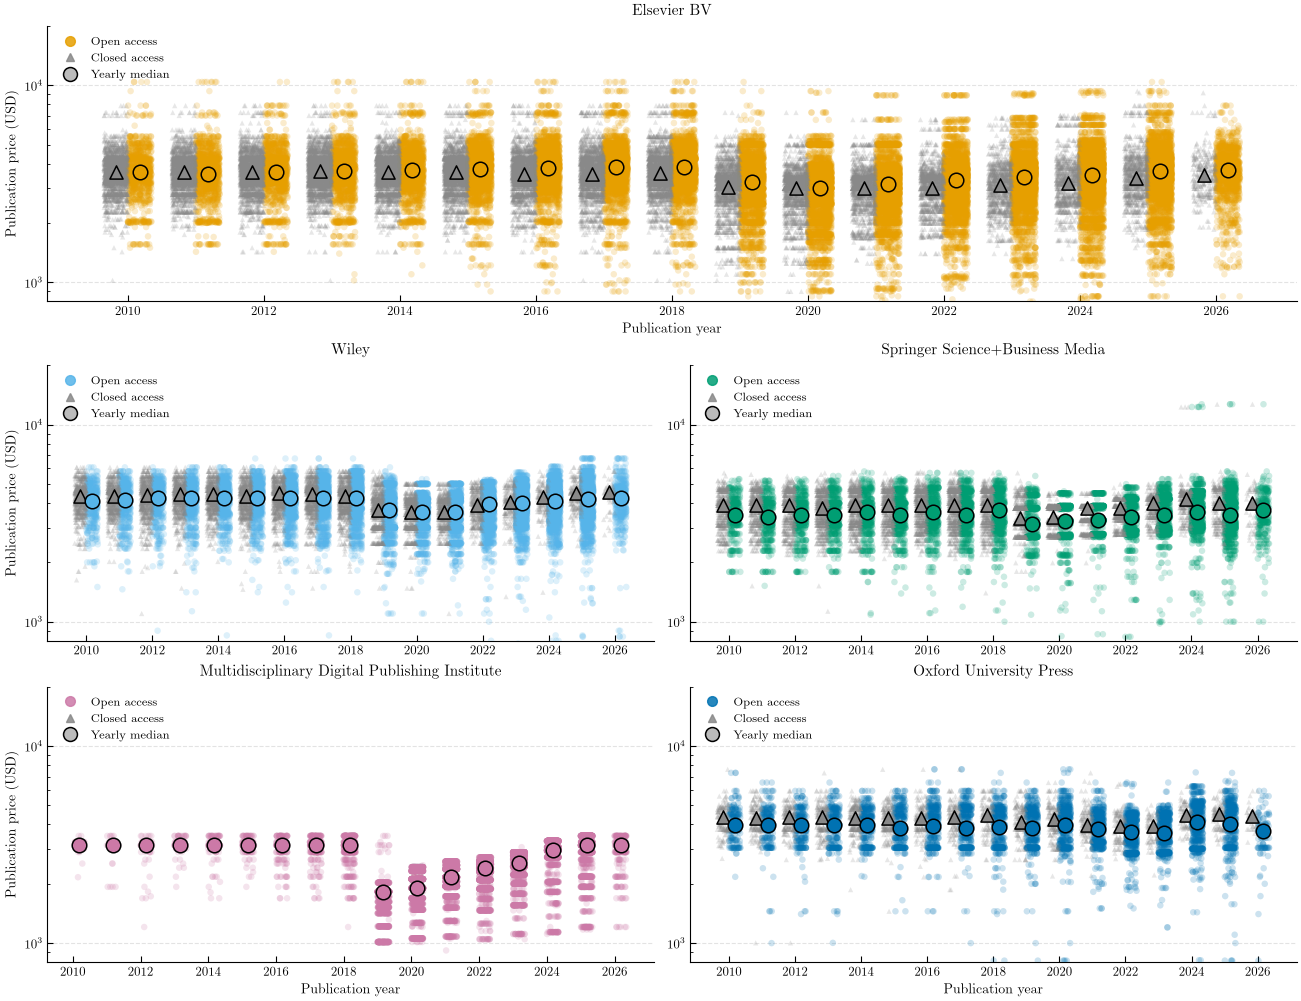

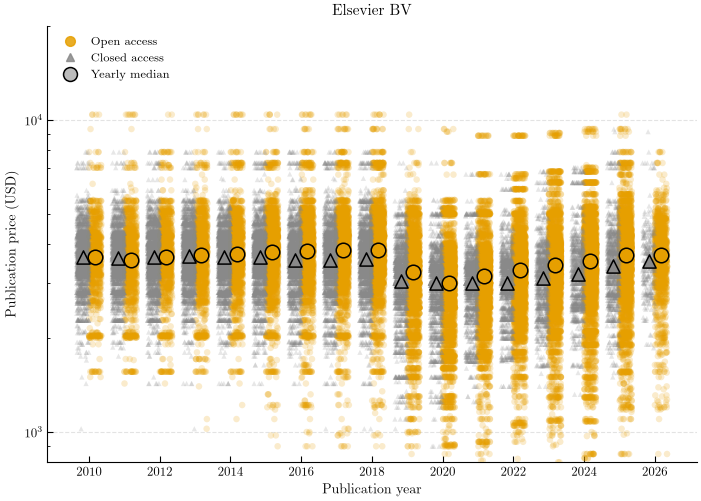

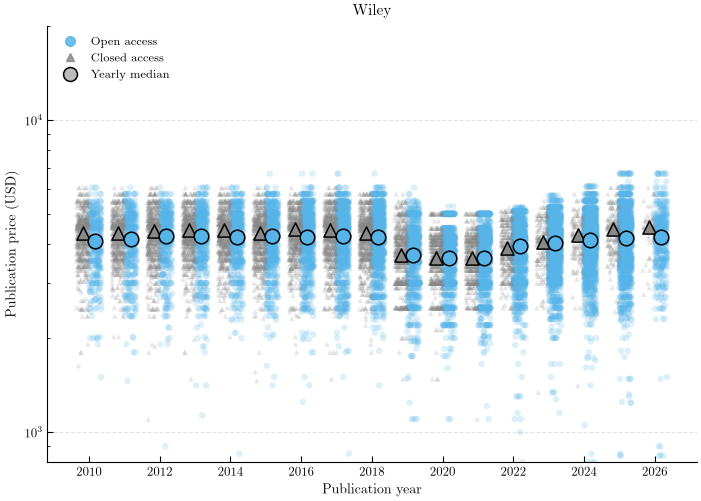

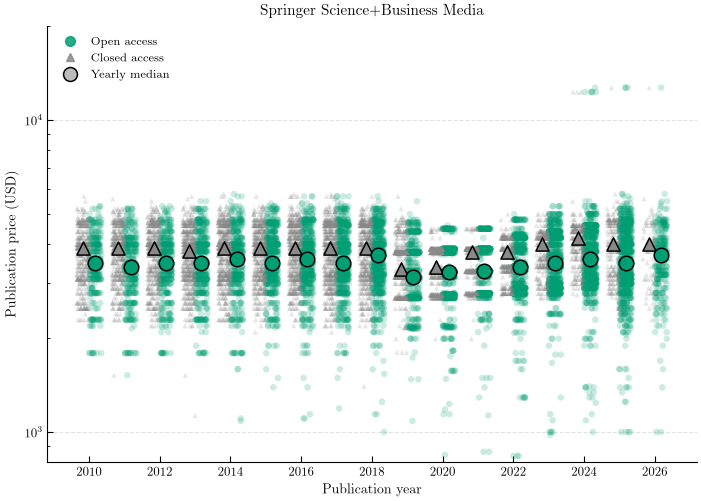

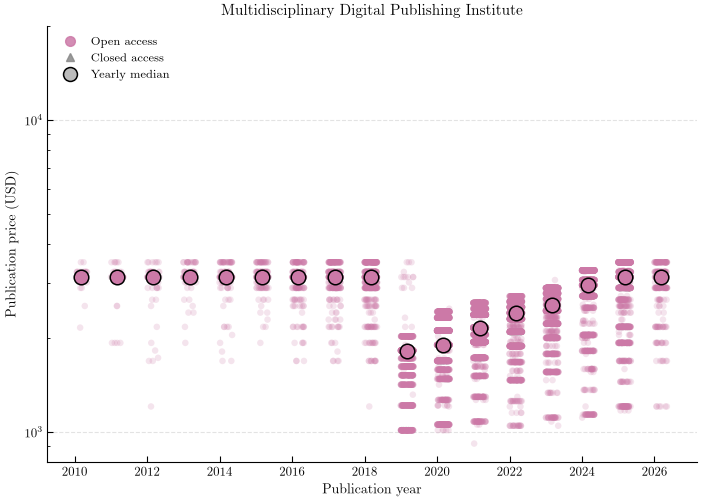

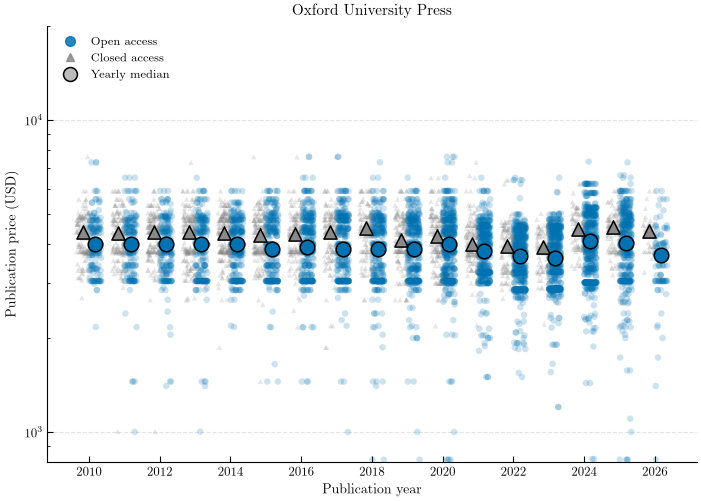

In [15]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D


OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#CC79A7', '#0072B2']
CLOSED_COLOR = "#898989"


# ---------------------------------------------------------------------------
# Helpers compartidos
# ---------------------------------------------------------------------------
def _prep_data(df, publishers, *, value_col, oa_column,
               min_year, max_year, drop_zero, jitter, seed):
    data = df.dropna(
        subset=["year", value_col, oa_column, "publisher_name"]
    ).copy()
    data = data[data["publisher_name"].isin(publishers)]
    if min_year is not None:
        data = data[data["year"] >= min_year]
    if max_year is not None:
        data = data[data["year"] <= max_year]
    if drop_zero:
        data = data[data[value_col] > 0]
    if data.empty:
        raise ValueError("No data left after filtering.")

    rng = np.random.default_rng(seed)
    data["_x"] = data["year"].astype(float) + rng.uniform(
        0, jitter, len(data)
    ) * data[oa_column].map({True: 1, False: -1})
    return data


def _shared_ylims(data, value_col, log_y, pad=0.05):
    vmin = float(data[value_col].min())
    vmax = float(data[value_col].max())
    if log_y and vmin > 0:
        return (vmin * 10 ** (-pad), vmax * 10 ** (pad))
    span = vmax - vmin if vmax > vmin else 1.0
    return (vmin - pad * span, vmax + pad * span)


def _style_axis(ax, *, log_y, x_major):
    if log_y:
        ax.set_yscale("log")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, which="major", axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)
    if x_major is not None:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(x_major))


def _draw_publisher(ax, sub, pub, color, *, value_col, oa_column,
                    log_y, show_medians, min_n_median, jitter,
                    x_major=2, legend=True):
    if sub.empty:
        ax.text(0.5, 0.5, "No data after filters",
                transform=ax.transAxes, ha="center", va="center",
                fontsize=10, color="#888")
    else:
        open_ = sub[sub[oa_column]]
        closed = sub[~sub[oa_column]]
        if not closed.empty:
            ax.scatter(
                closed["_x"], closed[value_col],
                s=14, marker="^", color=CLOSED_COLOR, alpha=0.2,
                edgecolors="none", rasterized=True, zorder=4,
            )
        if not open_.empty:
            ax.scatter(
                open_["_x"], open_[value_col],
                s=22, marker="o", color=color, alpha=0.2,
                edgecolors="none", rasterized=True, zorder=3,
            )

        # Medianas como PUNTOS resaltados (sin línea de evolución)
        if show_medians:
            med = (
                sub.groupby(["year", oa_column])[value_col]
                   .agg(["median", "count"]).reset_index()
            )
            med = med[med["count"] >= min_n_median]
            for is_oa, marker, base_color, size, jitter_mult in [
                (False, "^", CLOSED_COLOR, 90, -1),
                (True,  "o", color,        110, 1),
            ]:
                m = med[med[oa_column] == is_oa]
                if not m.empty:
                    ax.scatter(
                        m["year"]+jitter/2*jitter_mult, m["median"],
                        s=size, marker=marker, color=base_color,
                        edgecolors="black", linewidths=1.1, zorder=6,
                    )

    _style_axis(ax, log_y=log_y, x_major=x_major)
    ax.set_title(pub, pad=8, fontsize=11, weight="semibold")

    if legend:
        handles = [
            Line2D([0], [0], marker="o", linestyle="", markersize=7,
                   color=color, alpha=0.85, label="Open access"),
            Line2D([0], [0], marker="^", linestyle="", markersize=6,
                   color=CLOSED_COLOR, alpha=0.85, label="Closed access"),
        ]
        if show_medians:
            handles.append(
                Line2D([0], [0], marker="o", linestyle="", markersize=10,
                       markerfacecolor="#BBBBBB", markeredgecolor="black",
                       markeredgewidth=1.1, label="Yearly median")
            )
        ax.legend(handles=handles, loc="upper left",
                  frameon=False, fontsize=8.5)


# ---------------------------------------------------------------------------
# Panel 3x2
# ---------------------------------------------------------------------------
def plot_prices_panel(
    df: pd.DataFrame,
    publishers: list[str],
    *,
    value_col: str = "apc_list_value_usd",
    label_col: str = "Publication price ($)",
    oa_column: str = "is_open_access",
    min_year: int | None = None,
    max_year: int | None = None,
    drop_zero: bool = True,
    log_y: bool = True,
    jitter: float = 0.30,
    seed: int = 42,
    show_medians: bool = False,
    min_n_median: int = 5,
    shared_y: bool = True,
    ylim: tuple | None = None,
    x_major: int | None = 2,
    save_path: Path | None = None,
    figsize: tuple = (13, 10),
):
    data = _prep_data(
        df, publishers,
        value_col=value_col, oa_column=oa_column,
        min_year=min_year, max_year=max_year,
        drop_zero=drop_zero, jitter=jitter, seed=seed,
    )
    color_of = {p: OKABE_ITO[i % len(OKABE_ITO)]
                for i, p in enumerate(publishers)}

    fig = plt.figure(figsize=figsize, constrained_layout=True)
    gs = fig.add_gridspec(3, 2)
    slots = [gs[0, :], gs[1, 0], gs[1, 1], gs[2, 0], gs[2, 1]]

    axes, first_ax = [], None
    for i, pub in enumerate(publishers[:5]):
        ax = fig.add_subplot(slots[i], sharey=first_ax)
        if first_ax is None:
            first_ax = ax
        axes.append(ax)
        _draw_publisher(
            ax, data[data["publisher_name"] == pub], pub, color_of[pub],
            value_col=value_col, oa_column=oa_column,
            log_y=log_y, show_medians=show_medians, jitter=jitter,
            min_n_median=min_n_median, x_major=x_major,
        )

    if ylim is not None:
        first_ax.set_ylim(*ylim)
    elif shared_y:
        first_ax.set_ylim(*_shared_ylims(data, value_col, log_y))

    y_label_panels = {0, 1, 3}
    x_label_panels = {0, 3, 4}
    for i, ax in enumerate(axes):
        if i in y_label_panels:
            ax.tick_params(labelleft=True)
            ax.set_ylabel(label_col)
        else:
            ax.set_ylabel("")
        ax.set_xlabel("Publication year" if i in x_label_panels else "")

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        if save_path.suffix.lower() != ".pdf":
            fig.savefig(save_path.with_suffix(".pdf"), bbox_inches="tight")

    return fig, axes


# ---------------------------------------------------------------------------
# Un plot por editorial
# ---------------------------------------------------------------------------
def plot_prices_individual(
    df: pd.DataFrame,
    publishers: list[str],
    *,
    value_col: str = "apc_list_value_usd",
    label_col: str = "Publication price ($)",
    oa_column: str = "is_open_access",
    min_year: int | None = None,
    max_year: int | None = None,
    drop_zero: bool = True,
    log_y: bool = True,
    jitter: float = 0.30,
    seed: int = 42,
    show_medians: bool = False,
    min_n_median: int = 5,
    shared_y: bool = True,
    ylim: tuple | None = None,
    x_major: int | None = 2,
    save_dir: Path | None = None,
    filename_prefix: str = "price",
    figsize: tuple = (7, 5),
):
    """
    Genera un único figure por cada editorial en `publishers`.
    Devuelve una lista de tuplas (fig, ax, publisher).
    """
    data = _prep_data(
        df, publishers,
        value_col=value_col, oa_column=oa_column,
        min_year=min_year, max_year=max_year,
        drop_zero=drop_zero, jitter=jitter, seed=seed,
    )
    color_of = {p: OKABE_ITO[i % len(OKABE_ITO)]
                for i, p in enumerate(publishers)}

    if ylim is not None:
        ylims = ylim
    elif shared_y:
        ylims = _shared_ylims(data, value_col, log_y)
    else:
        ylims = None

    out = []
    for pub in publishers:
        fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
        _draw_publisher(
            ax, data[data["publisher_name"] == pub], pub, color_of[pub],
            value_col=value_col, oa_column=oa_column, jitter=jitter,
            log_y=log_y, show_medians=show_medians,
            min_n_median=min_n_median, x_major=x_major,
        )
        ax.set_xlabel("Publication year")
        ax.set_ylabel(label_col)
        if ylims is not None:
            ax.set_ylim(*ylims)

        if save_dir is not None:
            sd = Path(save_dir)
            sd.mkdir(parents=True, exist_ok=True)
            safe = re.sub(r"[^A-Za-z0-9_\-]+", "_", pub).strip("_")
            fig.savefig(sd / f"{filename_prefix}_{safe}.png",
                        dpi=300, bbox_inches="tight")
            fig.savefig(sd / f"{filename_prefix}_{safe}.pdf",
                        bbox_inches="tight")

        out.append((fig, ax, pub))
    return out


# ---------------------------------------------------------------------------
# Usage
# ---------------------------------------------------------------------------
TOP5 = [
    "Elsevier BV",
    "Wiley",
    "Springer Science+Business Media",
    "Multidisciplinary Digital Publishing Institute",
    "Oxford University Press",
]

COMMON = dict(
    value_col="apc_list_value_usd",
    label_col=r"Publication price (USD)",
    min_year=2010,
    jitter=0.35,
    show_medians=True,
    shared_y=True,
    ylim=(8e2, 2e4),
    x_major=2,
)

# 1) Panel 3x2
fig, axes = plot_prices_panel(
    df, TOP5,
    save_path=FIGS / "prices_panel_top5_publishers.png",
    **COMMON,
)

# 2) Cinco plots separados
individual_figs = plot_prices_individual(
    df, TOP5,
    save_dir=FIGS / "individual_publishers",
    **COMMON,
)

plt.show()

## How many money is spent on each domain to publication fees for the top 5 publishers?

In [16]:
TOP5 = [
    "Elsevier BV",
    "Wiley",
    "Springer Science+Business Media",
    "Multidisciplinary Digital Publishing Institute",
    "Oxford University Press",
]
aggregation = df.copy()
# 1) Create the grouping column
aggregation['publisher_group'] = aggregation['publisher_name'].where(
    aggregation['publisher_name'].isin(TOP5), 'Other'
)

# 2) Aggregate by sum (keeping domain_name)
aggregated = (
    aggregation.groupby(['domain_name', 'publisher_group', 'year'], as_index=False)['apc_list_value_usd']
      .sum()
      .rename(columns={'apc_list_value_usd': 'apc_total_usd', 'domain_name': 'Domain', 'publisher_group': 'Publisher'})
      .sort_values(['year'])
)

aggregated.to_csv(PROCESSED / "apc_total_by_domain_and_publisher_sankey.csv", index=False)

In [17]:
import pandas as pd
import lib.alluvial as alluvial  # Make sure alluvial.py is in your working directory
import matplotlib.pyplot as plt
from tqdm import tqdm

def wrap_text(text, width=15):
    """
    Wrap text into lines of at most `width` characters.
    
    - Breaks on whitespace where possible.
    - Hard-breaks any single word longer than `width`.
    - Collapses existing runs of whitespace (spaces, tabs, newlines) to single spaces.
    
    Returns a single string with '\n' between lines.
    """
    if text is None:
        return ""
    text = str(text)

    # Split on any whitespace; this also handles pre-existing newlines/tabs.
    words = text.split()
    if not words:
        return ""

    lines = []
    current = ""

    for word in words:
        # Hard-break words that are longer than the allowed width.
        while len(word) > width:
            if current:
                lines.append(current)
                current = ""
            lines.append(word[:width])
            word = word[width:]
        if not word:
            continue

        if not current:
            current = word
        elif len(current) + 1 + len(word) <= width:
            current += " " + word          # fits: append with a space
        else:
            lines.append(current)          # doesn't fit: start a new line
            current = word

    if current:
        lines.append(current)

    return "\n".join(lines)

colors = ['#E69F00', "#7F7F7F", '#56B4E9', '#009E73', '#CC79A7', '#0072B2']

# Load your CSV
csv = pd.read_csv(PROCESSED / "apc_total_by_domain_and_publisher_sankey.csv")   # or use the simulated df from above
csv = csv[csv['year'] > 2005]  # Filter out years before 1980
ALLUVIALS = FIGS/"alluvial"
ALLUVIALS.mkdir(exist_ok=True, parents=True)
# display(df)
# Build a nested dictionary: {source_category: {target_category: total_volume, ...}, ...}
for i, year in tqdm(list(enumerate(sorted(csv['year'].unique())))):
    input_data = {}
    csv_year = csv[csv['year'] == year]
    for _, row in csv_year.iterrows():
        src = row['Domain']
        tgt = wrap_text(row['Publisher'], 17)
        vol = row["apc_total_usd"]
        if src not in input_data:
            input_data[src] = {}
        # If multiple rows have the same (src, tgt), sum their volumes
        input_data[src][tgt] = input_data[src].get(tgt, 0) + vol


    # Plot using the standalone script
    ax = alluvial.plot(input_data, color_side=1, colors=colors[::-1], alpha=0.8)
    ax.set_title("Spent money in publication fees by domain and publisher in " + str(year))
    ax.figure.savefig(ALLUVIALS/f"{i}_alluvial.png", dpi=200)
    plt.close()
    # plt.show()

100%|██████████| 21/21 [00:02<00:00,  7.04it/s]


In [18]:
# only execute if ffmpeg is present in your system, otherwise comment out the following line!!!!!
! ffmpeg -y -f image2 -framerate 2 -i {ALLUVIALS/"%d_alluvial.png"} -vf "scale=1200:-1:flags=lanczos,split[s0][s1];[s0]palettegen=max_colors=256[p];[s1][p]paletteuse=dither=sierra2_4a" -loop 0 {FIGS/"alluvial.gif"}

ffmpeg version 8.1.3 Copyright (c) 2000-2026 the FFmpeg developers
  built with gcc 16 (GCC)
  configuration: --prefix=/usr --bindir=/usr/bin --datadir=/usr/share/ffmpeg --docdir=/usr/share/doc/ffmpeg --incdir=/usr/include/ffmpeg --libdir=/usr/lib64 --mandir=/usr/share/man --arch=aarch64 --optflags='-O2 -flto=auto -ffat-lto-objects -fexceptions -g -grecord-gcc-switches -pipe -Wall -Werror=format-security -Wno-error=incompatible-pointer-types -Wp,-U_FORTIFY_SOURCE,-D_FORTIFY_SOURCE=3 -Wp,-D_GLIBCXX_ASSERTIONS -specs=/usr/lib/rpm/redhat/redhat-hardened-cc1 -fstack-protector-strong -specs=/usr/lib/rpm/redhat/redhat-annobin-cc1 -mbranch-protection=standard -fasynchronous-unwind-tables -fstack-clash-protection -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer ' --extra-cflags=-I/usr/include/decklink --extra-cxxflags=-I/usr/include/decklink --extra-ldflags='-Wl,-z,relro -Wl,--as-needed -Wl,-z,pack-relative-relocs -Wl,-z,now -specs=/usr/lib/rpm/redhat/redhat-hardened-ld -specs=/usr/lib/rpm